In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
import datetime as dt
# Optional imports for visualization
try:
  import plotly.graph_objects as go
  PLOTLY_OK = True
except ImportError:
  PLOTLY_OK = False
np.random.seed(42)


In [26]:
# --- Step 1: Simulate Clickstream Data ---
pages = ["Landing", "Category", "Product", "Cart", "Checkout", "Purchase", "Search", "Help"]
devices = ["mobile", "desktop", "tablet"]

next_probs = {
    "Landing": {"Category": 0.35, "Search": 0.20, "Product": 0.15, "Help": 0.05, "Exit": 0.25},
    "Category": {"Product": 0.45, "Search": 0.15, "Landing": 0.05, "Help": 0.05, "Exit": 0.30},
    "Search": {"Product": 0.40, "Category": 0.15, "Landing": 0.10, "Help": 0.05, "Exit": 0.30},
    "Product": {"Cart": 0.35, "Category": 0.15, "Search": 0.10, "Help": 0.05, "Exit": 0.35},
    "Cart": {"Checkout": 0.55, "Product": 0.10, "Exit": 0.35},
    "Checkout": {"Purchase": 0.55, "Cart": 0.10, "Exit": 0.35},
    "Purchase": {"Exit": 1.0},
    "Help": {"Landing": 0.20, "Search": 0.20, "Exit": 0.60}
}


In [27]:
def sample_next(curr):
  choices, probs = zip(*next_probs[curr].items())
  return np.random.choice(choices, p=probs)
def simulate_session(session_id, start_time):
  device = np.random.choice(devices, p=[0.55, 0.35, 0.10])
  curr = "Landing"
  t = start_time
  path = []
  for _ in range(np.random.randint(3, 10)):
    path.append((session_id, t, curr, device))
    nxt = sample_next(curr)
    if nxt == "Exit":
      break
    t += dt.timedelta(seconds=np.random.randint(5, 60))
    curr = nxt
  return path


In [29]:
rows = []
base_time = dt.datetime(2024, 10, 1, 8, 0, 0)
for s in range(300):
  start = base_time + dt.timedelta(minutes=np.random.randint(0, 600))
  rows.extend(simulate_session(f"S{s:04d}", start))
  df = pd.DataFrame(rows, columns=["SessionID", "Timestamp", "Page", "Device"])
  print(df.head())
# Step 2: Funnel Analysis We define the funnel: `Landing → Product → Cart → Che
funnel = ["Landing", "Product", "Cart", "Checkout", "Purchase"]
session_pages = df.groupby("SessionID")["Page"].apply(list)


  SessionID           Timestamp      Page   Device
0     S0000 2024-10-01 09:42:00   Landing  desktop
1     S0000 2024-10-01 09:42:25      Help  desktop
2     S0000 2024-10-01 09:42:48   Landing  desktop
3     S0000 2024-10-01 09:43:03  Category  desktop
  SessionID           Timestamp      Page   Device
0     S0000 2024-10-01 09:42:00   Landing  desktop
1     S0000 2024-10-01 09:42:25      Help  desktop
2     S0000 2024-10-01 09:42:48   Landing  desktop
3     S0000 2024-10-01 09:43:03  Category  desktop
4     S0001 2024-10-01 09:39:00   Landing   mobile
  SessionID           Timestamp      Page   Device
0     S0000 2024-10-01 09:42:00   Landing  desktop
1     S0000 2024-10-01 09:42:25      Help  desktop
2     S0000 2024-10-01 09:42:48   Landing  desktop
3     S0000 2024-10-01 09:43:03  Category  desktop
4     S0001 2024-10-01 09:39:00   Landing   mobile
  SessionID           Timestamp      Page   Device
0     S0000 2024-10-01 09:42:00   Landing  desktop
1     S0000 2024-10-01 09:42:25

In [30]:
def reached_stages(pages):
  idx = 0
  result = {stage: False for stage in funnel}
  for p in pages:
    if p == funnel[idx]:
      result[funnel[idx]] = True
    if idx < len(funnel) - 1:
      idx += 1
  return result
reached_df = session_pages.apply(reached_stages).apply(pd.Series)
stage_counts = reached_df.sum()

In [31]:
# Conversion rates
conv_rates = {}
for i in range(len(funnel) - 1):
  curr_stage = funnel[i]
  next_stage = funnel[i + 1]
  denom = reached_df[curr_stage].sum()
  num = (reached_df[curr_stage] & reached_df[next_stage]).sum()
  conv_rates[f"{curr_stage} → {next_stage}"] = num / denom if denom else 0
print("Stage Counts:\n", stage_counts)
print("\nConversion Rates:\n", conv_rates)

Stage Counts:
 Landing     300
Product      47
Cart         18
Checkout     10
Purchase      5
dtype: int64

Conversion Rates:
 {'Landing → Product': np.float64(0.15666666666666668), 'Product → Cart': np.float64(0.3829787234042553), 'Cart → Checkout': np.float64(0.5555555555555556), 'Checkout → Purchase': np.float64(0.4)}


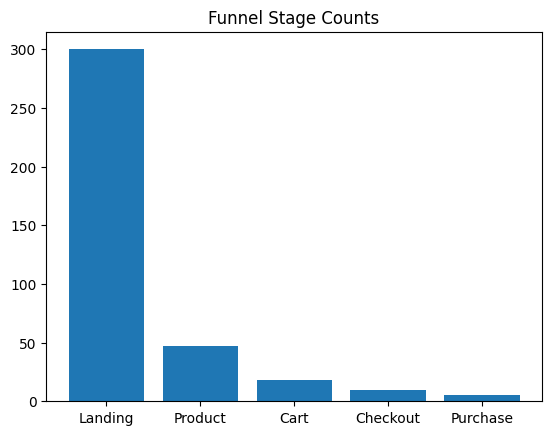

In [32]:
# Bar chart
plt.bar(funnel, [stage_counts[s] for s in funnel])
plt.title("Funnel Stage Counts")
plt.show()

In [34]:
# Step 3: Common Paths - Find the most common 3-step sequences.
def ngrams(seq, n):
  return list(zip(*[seq[i:] for i in range(n)]))
trigram_counts = Counter()
for path in session_pages:
  trigram_counts.update(ngrams(path, 3))
print("Top 5 trigrams:")
for trigram, count in trigram_counts.most_common(5):
  print(trigram, count)

Top 5 trigrams:
('Landing', np.str_('Category'), np.str_('Product')) 45
('Landing', np.str_('Search'), np.str_('Product')) 30
(np.str_('Product'), np.str_('Cart'), np.str_('Checkout')) 19
('Landing', np.str_('Product'), np.str_('Cart')) 18
('Landing', np.str_('Category'), np.str_('Search')) 16


In [37]:
# Step 4: Optional Sankey Diagram
if PLOTLY_OK:
    # 1. Define nodes dynamically using the funnel steps
    labels = funnel

    # 2. Map sources to targets sequentially (0 -> 1, 1 -> 2, etc.)
    source = list(range(len(funnel) - 1))
    target = list(range(1, len(funnel)))

    # 3. Calculate values: Count how many users reached step i+1
    # (Fixed the undefined 'r' loop and column-intersection syntax)
    value = [int(reached_df[funnel[i+1]].sum()) for i in range(len(funnel) - 1)]

    # 4. Generate the interactive visualization
    fig = go.Figure(data=[go.Sankey(
        node=dict(label=labels, pad=15, thickness=20, color="royalblue"),
        link=dict(source=source, target=target, value=value, color="lightblue")
    )])

    fig.update_layout(title_text="User Conversion Funnel Flow", font_size=12)
    fig.show()
else:
    print("Plotly not installed, skipping Sankey.")
